<a href="https://colab.research.google.com/github/saeemandarpetkar-coder/google-collab/blob/main/exp_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Logistic regression
### step1:Data collection
Importing libraries

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math

In [8]:
titanic_data = pd.read_csv('/content/titanic_data.csv')

In [ ]:
titanic_data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [9]:
print(str(len(titanic_data.index)))

891


Step 2 : Analyzing the data

!!! knowing the data !!! plotting graphs !!! EDA

<Axes: xlabel='Survived', ylabel='count'>

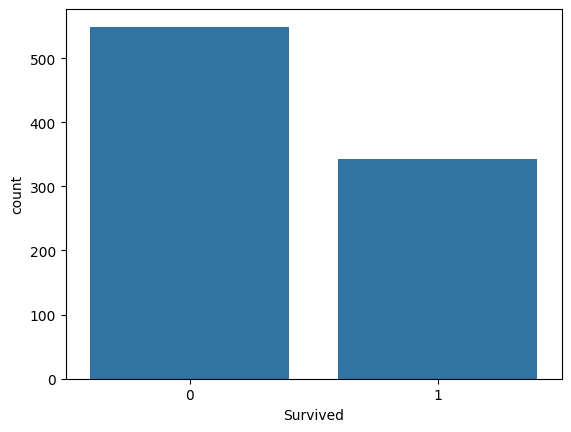

In [10]:
#knowing how many people survived and died
sns.countplot(x='Survived',data=titanic_data)

<Axes: xlabel='Survived', ylabel='count'>

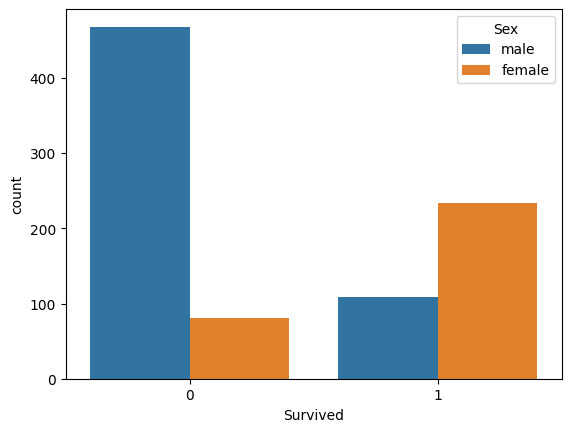

In [11]:
#knowing how many male survived and how many females survived
sns.countplot(x='Survived',hue='Sex',data=titanic_data)

<Axes: xlabel='Survived', ylabel='count'>

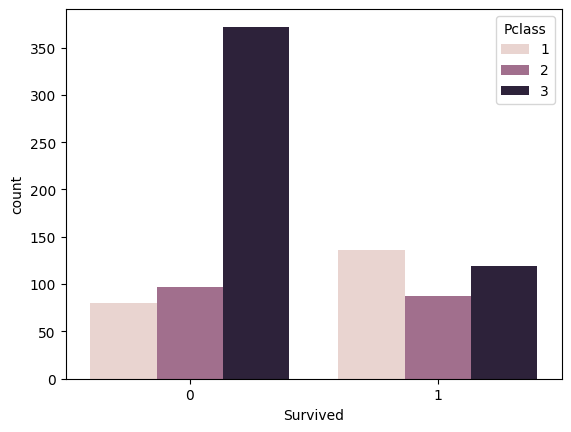

In [12]:
#Knowing which class people survived the most
sns.countplot(x='Survived',hue='Pclass',data=titanic_data)

<Axes: ylabel='Frequency'>

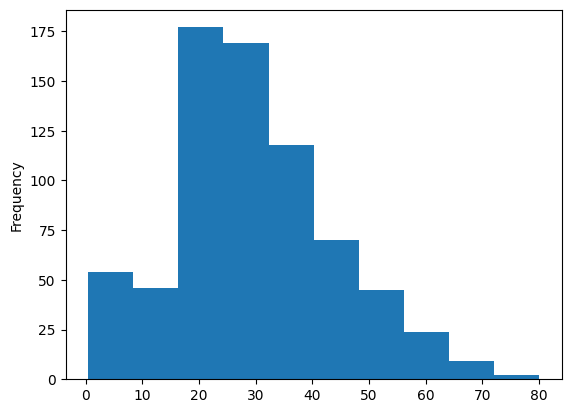

In [13]:
#Age distribution
titanic_data['Age'].plot.hist()

<Axes: ylabel='Frequency'>

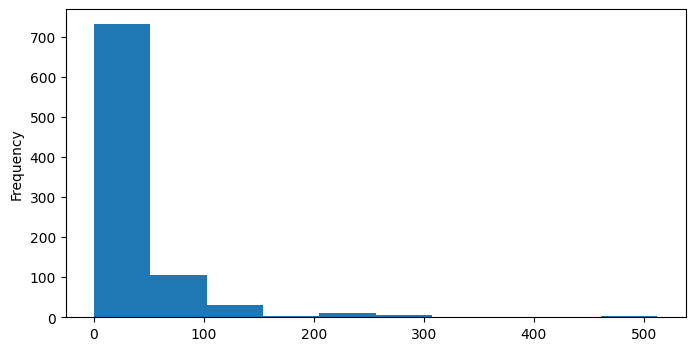

In [14]:
#fare- the amount of money a passenger paid for their tickit
titanic_data['Fare'].plot.hist(figsize=(8,4))

Exploratory data Analysis

In [15]:
titanic_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


### Step 3 : Data Preprocessing

!!! Data cleaning (Removing impurities) !!! Imputation

In [16]:
titanic_data.isnull()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,False,False,False,False,False,False,False,False,False,False,True,False
1,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,True,False
3,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...
886,False,False,False,False,False,False,False,False,False,False,True,False
887,False,False,False,False,False,False,False,False,False,False,False,False
888,False,False,False,False,False,True,False,False,False,False,True,False
889,False,False,False,False,False,False,False,False,False,False,False,False


In [17]:
titanic_data.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


#imputation
titanic_data.drop('Cabin',axis=1,inplace=True)

In [18]:
titanic_data.head(2)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C


In [19]:
titanic_data.dropna(inplace=True)

In [20]:
titanic_data.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


Converting data from one form to another

In [21]:
titanic_data.head(5)
# we will first convert categorical variables into dummy variabls and then use them as logistic reg only takes 2 inputs

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
10,11,1,3,"Sandstrom, Miss. Marguerite Rut",female,4.0,1,1,PP 9549,16.7000,G6,S
11,12,1,1,"Bonnell, Miss. Elizabeth",female,58.0,0,0,113783,26.5500,C103,S


In [22]:
titanic_data.head(5)
# we will first convert categorical variables into dummy variabls and then use them as logistic reg only takes 2 inputs

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
10,11,1,3,"Sandstrom, Miss. Marguerite Rut",female,4.0,1,1,PP 9549,16.7000,G6,S
11,12,1,1,"Bonnell, Miss. Elizabeth",female,58.0,0,0,113783,26.5500,C103,S


Encoding

Using logistic regression we will predict how many people survived and how many died in titanic ship. here 1 survived and 0 died.

In [23]:
pd.get_dummies(titanic_data['Sex']).astype(int)

,female,male
1,1,0
3,1,0
6,0,1
10,1,0
11,1,0
...,...,...
871,1,0
872,0,1
879,1,0
887,1,0


In [24]:
S = pd.get_dummies(titanic_data['Sex'],drop_first=True).astype(int)
S.head(4)

,male
1,0
3,0
6,1
10,0


In [25]:
#conversion of Embarked column from one form to another
#Q= Quinstown, S=southam , C= chambor
E = pd.get_dummies(titanic_data['Embarked'],drop_first=True).astype(int).astype(int)
E.head(4)

,Q,S
1,0,0
3,0,1
6,0,1
10,0,1


In [26]:
#conversion of Pclass column from one form to another
P = pd.get_dummies(titanic_data['Pclass'],drop_first=True).astype(int).astype(int)
P.head(4)

,2,3
1,0,0
3,0,0
6,0,0
10,0,1


In [27]:
#concatinate all the new rows in the dataset
titanic_data = pd.concat([titanic_data,S,E,P],axis=1)

In [28]:
titanic_data.head(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,male,Q,S,2,3
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,0,0,0,0,0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,0,0,1,0,0
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S,1,0,1,0,0
10,11,1,3,"Sandstrom, Miss. Marguerite Rut",female,4.0,1,1,PP 9549,16.7000,G6,S,0,0,1,0,1
11,12,1,1,"Bonnell, Miss. Elizabeth",female,58.0,0,0,113783,26.5500,C103,S,0,0,1,0,0


In [29]:
titanic_data.drop(['Sex','Embarked','PassengerId','Name','Ticket','Pclass'],axis=1,inplace=True)

In [30]:
#our final dataset
titanic_data.head(5)

,Survived,Age,SibSp,Parch,Fare,Cabin,male,Q,S,2,3
1,1,38.0,1,0,71.2833,C85,0,0,0,0,0
3,1,35.0,1,0,53.1000,C123,0,0,1,0,0
6,0,54.0,0,0,51.8625,E46,1,0,1,0,0
10,1,4.0,1,1,16.7000,G6,0,0,1,0,1
11,1,58.0,0,0,26.5500,C103,0,0,1,0,0


### Step 4 : Split Training and testing the data

Train Data

In [31]:
X = titanic_data.drop('Survived',axis=1)# accept survived all the other columns are indep var
y = titanic_data['Survived']

splitting the data



In [32]:
from sklearn.model_selection import train_test_split

In [33]:
train_test_split

<function sklearn.model_selection._split.train_test_split(*arrays, test_size=None, train_size=None, random_state=None, shuffle=True, stratify=None)>

In [34]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=1)

Implementing logistic regression

!!! Creating our Model

In [35]:
from sklearn.linear_model import LogisticRegression

In [36]:
model = LogisticRegression()

In [ ]:
X_train.columns = X_train.columns.astype(str)
model.fit(X_train,y_train)

In [48]:
#X_test.columns = X_test.columns.astype(str)
predictions = model.predict(X_test)

### Step 5 : Predictions

In [49]:
print("Predictions:")
print(predictions)

Predictions:
[1 0 1 1 1 0 1 1 1 1 1 1 0 1 1 1 1 0 1 1 0 1 1 0 1 1 0 1 1 1 1 0 1 1 0 0 1
 1 1 1 0 1 1 1 1 0 1 1 1 0 1 1 0 1 0]


import matplotlib.pyplot as plt

In [50]:
# Assuming you already have your trained model and test data
# model.fit(X_train, y_train)
predictions = model.predict(X_test)

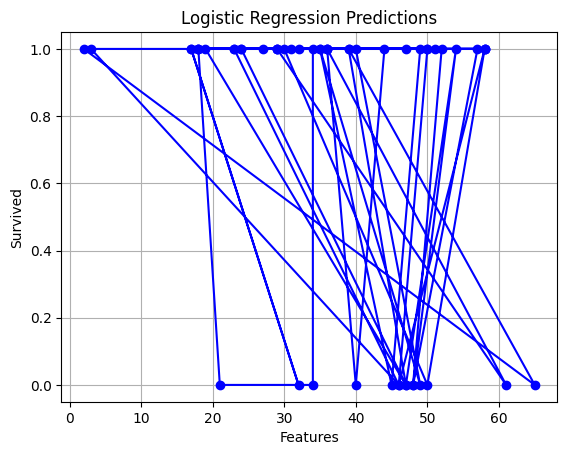

In [51]:
# Plot predicted classes vs the first feature of X_test
plt.plot(X_test.iloc[:, 0], predictions, marker='o', linestyle='-', color='blue')
plt.xlabel('Features')
plt.ylabel('Survived')
plt.title('Logistic Regression Predictions')
plt.grid(True)
plt.show()

In [52]:
from sklearn.metrics import confusion_matrix

In [53]:
print(confusion_matrix(y_test,predictions))

[[ 9  8]
 [ 6 32]]


Step 6 : Checking the Accuracy

In [54]:
from sklearn.metrics import accuracy_score

In [55]:
accuracy_score(y_test,predictions)

0.7454545454545455